In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np
from copy import deepcopy as cdc

from datetime import datetime as dt
import re
def extract_timestamps(series:pd.Series) -> pd.Series:
    timestamp = series.str.extract('_(\d{4}-[\-\d_T]*)DLC', expand=False)
    return pd.to_datetime(timestamp, format="%Y-%m-%dT%H_%M_%S")
##need to have filename column as type str in order for datetime extraction to be used, won't run on Posix type

import statsmodels.api as sm
from statsmodels.formula.api import ols
from scipy import stats

import prey_capture_python as preycap
import pingouin as pg

from scipy.stats import ranksums

In [33]:
df=pd.read_csv('/Users/mollyshallow/Desktop/WehrLab/Conferences/Rig3Phys_Data.csv')

In [34]:
df

,mouse,File,protocol,penetration,tot cells,T and/or WN Linc,center/surround,Linc,T and/or WN no L,T and/or WN Ldec,...,%noL,Unnamed: 30,no sound,%cells,Linc_ns,Ldec_ns,%Linc_ns,%Ldec_ns,no_response,noL
0,2810.0,2024-07-26_8-41-58_mouse-2810,CT,1.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2810.0,2024-07-26_9-11-43_mouse-2810,LT,1.0,158.0,7.0,5.0,3.0,9.0,0.0,...,42.857143,NaN,137.0,86.708861,3.0,0.0,2.189781,0.000000,134.0,97.810219
2,2810.0,2024-07-26_9-26-29_mouse-2810,TC,1.0,154.0,2.0,13.0,15.0,3.0,0.0,...,16.666667,NaN,136.0,88.311688,15.0,0.0,11.029412,0.000000,121.0,88.970588
3,2810.0,2024-07-26_9-58-58_mouse-2810,CT,1.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2810.0,2024-07-26_10-23-54_mouse-2810,PINP,1.0,107.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2810.0,2024-07-26_10-28-40_mouse-2810,LT,1.0,129.0,3.0,3.0,3.0,8.0,1.0,...,53.333333,NaN,114.0,88.372093,5.0,3.0,4.385965,2.631579,106.0,92.982456
6,2810.0,2024-07-26_10-42-52_mouse-2810,TC,1.0,150.0,2.0,13.0,2.0,2.0,0.0,...,11.764706,NaN,133.0,88.666667,5.0,0.0,3.759398,0.000000,128.0,96.240601
7,2810.0,2024-07-26_12-15-17_mouse-2810,CT,2.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2810.0,2024-07-26_12-40-11_mouse-2810,PINP,2.0,75.0,NaN,NaN,3.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2810.0,2024-07-26_13-03-11_mouse-2810,LT,2.0,132.0,0.0,1.0,0.0,2.0,1.0,...,50.000000,NaN,128.0,96.969697,1.0,2.0,0.781250,1.562500,125.0,97.656250


In [35]:
df.keys()

Index(['mouse', 'File', 'protocol', 'penetration', 'tot cells',
       'T and/or WN Linc', 'center/surround', 'Linc', 'T and/or WN no L',
       'T and/or WN Ldec', 'RD Linc', 'Ldec', 'RD no L', 'L drive resp',
       '%TWNLinc', '%c/s', '%Linc', '%TWNnoL', '%TWNLdec', '%RDLinc', '%Ldec',
       '%RDnoL', '%Lresp', 'Unnamed: 23', 'sound responsive',
       '%sound responsive', '%Linc_ms', '%Ldec_ms', '%c/s_ms', '%noL',
       'Unnamed: 30', 'no sound', '%cells', 'Linc_ns', 'Ldec_ns', '%Linc_ns',
       '%Ldec_ns', 'no_response', 'noL'],
      dtype='object')

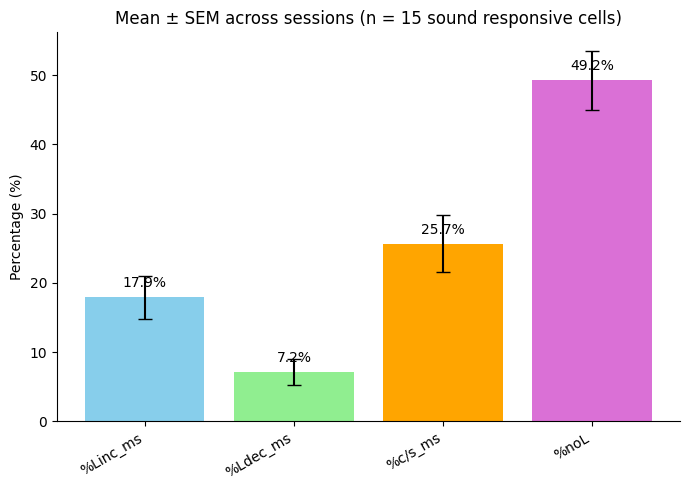

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Example DataFrame: df
metrics = ["%Linc_ms", "%Ldec_ms", "%c/s_ms", "%noL"]

# Compute means and SEMs
means = df[metrics].mean()
sems = df[metrics].sem()  # pandas sem() gives standard error of the mean

# Compute mean n (sound responsive cells)
mean_n = int(df["sound responsive"].mean())
total_cells=int(df['tot cells'])

# Create bar plot
fig, ax = plt.subplots(figsize=(7, 5))
x = np.arange(len(metrics))

bars = ax.bar(
    x,
    means,
    yerr=sems,
    capsize=5,
    color=["skyblue", "lightgreen", "orange", "orchid"],
    
)


# Labeling
ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=30, ha="right")
ax.set_ylabel("Percentage (%)")
ax.set_title(f"Mean ± SEM across sessions (n = {mean_n} sound responsive cells)")

# Annotate bar tops with mean values
for bar, val in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f"{val:.1f}%", ha='center', va='bottom', fontsize=10)

plt.tight_layout()
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/acute_cell_counts_bar.pdf')
plt.show()


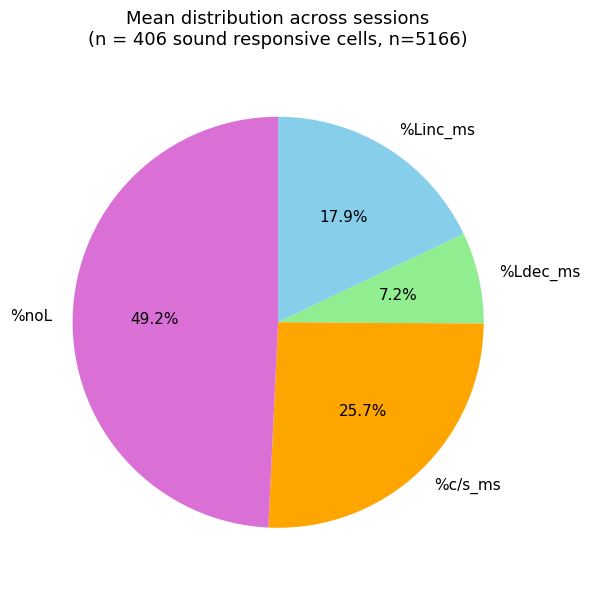

In [29]:


# Example DataFrame: df
metrics = ["%Linc_ms", "%Ldec_ms", "%c/s_ms", "%noL"]

# Compute means
means = df[metrics].mean()

# Compute mean n (sound responsive cells)
sum_n = int(df["sound responsive"].sum())
total_cells=int(df['tot cells'].sum())

# Pie chart
fig, ax = plt.subplots(figsize=(6, 6))

colors = ["skyblue", "lightgreen", "orange", "orchid"]
wedges, texts, autotexts = ax.pie(
    means,
    labels=metrics,
    autopct='%1.1f%%',
    colors=colors,
    startangle=90,
    counterclock=False,
    textprops={'fontsize': 11}
)

# Equal aspect ratio ensures the pie is circular
ax.axis('equal')
ax.set_title(f"Mean distribution across sessions\n(n = {sum_n} sound responsive cells, n={total_cells})", fontsize=13, pad=15)
# ax.set_title(f"(n = {sum_n} total cells)", fontsize=13, pad=15)

sns.despine(left=True, bottom=True)
plt.tight_layout()
# plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/acute_cell_counts_pie.pdf')
plt.show()



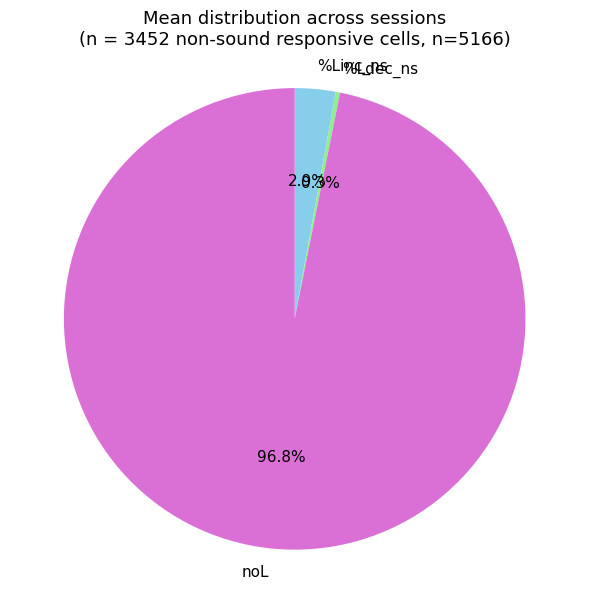

In [39]:


# Example DataFrame: df
metrics = ["%Linc_ns", "%Ldec_ns", "noL"]

# Compute means
means = df[metrics].mean()

# Compute mean n (sound responsive cells)
sum_n = int(df["no_response"].sum())
total_cells=int(df['tot cells'].sum())

# Pie chart
fig, ax = plt.subplots(figsize=(6, 6))

colors = ["skyblue", "lightgreen",  "orchid"]
wedges, texts, autotexts = ax.pie(
    means,
    labels=metrics,
    autopct='%1.1f%%',
    colors=colors,
    startangle=90,
    counterclock=False,
    textprops={'fontsize': 11}
)

# Equal aspect ratio ensures the pie is circular
ax.axis('equal')
ax.set_title(f"Mean distribution across sessions\n(n = {sum_n} non-sound responsive cells, n={total_cells})", fontsize=13, pad=15)
# ax.set_title(f"(n = {sum_n} total cells)", fontsize=13, pad=15)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/acute_cell_counts_nosound_pie.pdf')
plt.show()



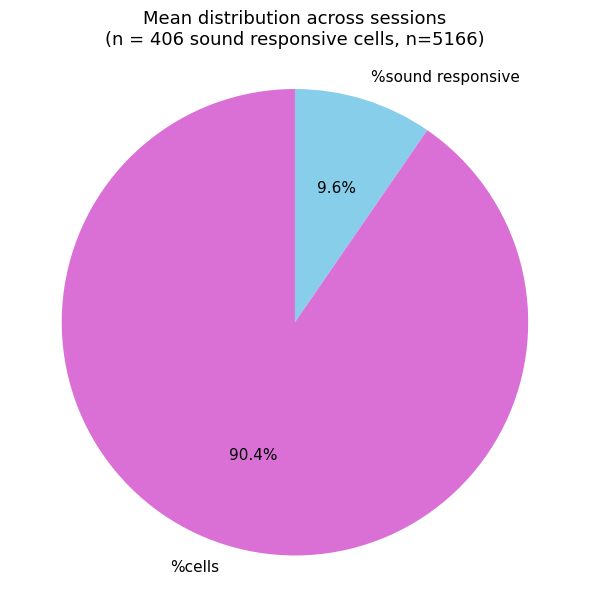

In [41]:


# Example DataFrame: df
metrics = ["%sound responsive", "%cells"]

# Compute means
means = df[metrics].mean()

# Compute mean n (sound responsive cells)
sum_n = int(df["sound responsive"].sum())
total_cells=int(df['tot cells'].sum())

# Pie chart
fig, ax = plt.subplots(figsize=(6, 6))

colors = ["skyblue", "orchid"]
wedges, texts, autotexts = ax.pie(
    means,
    labels=metrics,
    autopct='%1.1f%%',
    colors=colors,
    startangle=90,
    counterclock=False,
    textprops={'fontsize': 11}
)

# Equal aspect ratio ensures the pie is circular
ax.axis('equal')
ax.set_title(f"Mean distribution across sessions\n(n = {sum_n} sound responsive cells, n={total_cells})", fontsize=13, pad=15)
# ax.set_title(f"(n = {sum_n} total cells)", fontsize=13, pad=15)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/acute_total_cell_counts_pie.pdf')
plt.show()

